## Step 1 — Environment Setup and Global Configurations

In [1]:
# Import operating system and core numerical/tensor libraries
import os, torch, numpy as np
import matplotlib.pyplot as plt
from datasets import load_from_disk
from transformers import (BertTokenizer,
                          BertForSequenceClassification,
                          get_linear_schedule_with_warmup)
from torch.utils.data import DataLoader, TensorDataset
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score
from google.colab import drive

drive.mount('/content/drive')

DEVICE     = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CSV_PATH   = "/content/drive/MyDrive/Licenta/IMDB Dataset.csv"
MODEL_NAME = "bert-base-uncased"
BATCH_SIZE = 16
NUM_EPOCHS = 3

print(f"Device: {DEVICE}")

Mounted at /content/drive
Device: cuda


## Step 2 — Data Preprocessing and Tokenization Function

In [2]:
# Import pandas for data manipulation and re for regular expressions
import pandas as pd, re
from sklearn.model_selection import train_test_split

def prepare_data(max_length):
    """Tokenize and split dataset for a given max_length."""
    print(f"\nPreparing data with MAX_LENGTH={max_length}...")

    df = pd.read_csv(CSV_PATH) # Load the CSV file into a pandas DataFrame
    df.columns = ["text", "sentiment"] # Standardize column names
    df["label"] = df["sentiment"].map({"positive": 1, "negative": 0}) # Map string sentiments to binary integer labels
    df["text"] = df["text"].apply(lambda t: re.sub(r"\s+", " ",  # Clean text: remove HTML tags, replace multiple spaces with single space, and strip whitespace
                  re.sub(r"<.*?>", " ", t)).strip())
    df = df.drop_duplicates(subset=["text"]).reset_index(drop=True) # Drop duplicated rows based on text content to prevent data leakage

    # Split the full dataset into train/validation (85%) and test (15%) sets
    train_val, test_df = train_test_split(df, test_size=0.15,
                         random_state=42, stratify=df["label"])

    # Split the train_val set further into train (70% of total) and validation (15% of total)
    train_df, val_df   = train_test_split(train_val,
                         test_size=0.15/0.85,
                         random_state=42, stratify=train_val["label"])

    tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)

    # Helper function to tokenize text sequences to a specified max_length
    def tokenize(texts):
        return tokenizer(texts, truncation=True,
                         padding="max_length",
                         max_length=max_length,
                         return_tensors="pt")

    # Helper function to create PyTorch DataLoaders from DataFrames
    def make_loader(df, shuffle):
        enc = tokenize(df["text"].tolist()) # Tokenize all text entries in the dataset split
        labels = torch.tensor(df["label"].tolist(), dtype=torch.long) # Convert pandas labels to PyTorch tensors
        ds = TensorDataset(enc["input_ids"], # Group input IDs, attention masks, and labels into a TensorDataset
                           enc["attention_mask"], labels)
        return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle) # Wrap dataset in a DataLoader for batching and optional shuffling

    # Return DataLoaders for train (shuffled), validation (unshuffled), and test (unshuffled) sets
    return (make_loader(train_df, True),
            make_loader(val_df,   False),
            make_loader(test_df,  False))

## Step 3 — Model Training and Evaluation Logic

In [3]:
# Cell 3: Model Training and Evaluation Logic

import time

def train_and_evaluate(max_length):
    # Record the start time of the entire training and evaluation process
    total_start = time.time()
    # Retrieve the data loaders for the specific maximum token length
    train_loader, val_loader, test_loader = prepare_data(max_length)

    # Load pre-trained BERT model adapted for sequence classification (2 labels) and move it to the active device
    model = BertForSequenceClassification.from_pretrained(
                MODEL_NAME, num_labels=2).to(DEVICE)

    # Initialize the AdamW optimizer with learning rate and weight decay
    optimizer   = AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
    # Calculate total training steps for learning rate scheduling
    total_steps = len(train_loader) * NUM_EPOCHS
    # Create a learning rate scheduler with a linear warmup phase
    scheduler   = get_linear_schedule_with_warmup(
                      optimizer,
                      num_warmup_steps=int(0.1 * total_steps),
                      num_training_steps=total_steps)

    # Keep track of time taken per epoch
    epoch_times = []

    # Training loop over the specified number of epochs
    for epoch in range(NUM_EPOCHS):
        epoch_start = time.time()
        # Set model to training mode (enables dropout, gradients)
        model.train()
        total_loss, correct, total = 0, 0, 0

        # Iterate over batches in the training data loader
        for input_ids, attention_mask, labels in train_loader:
            # Move batch tensors to the target computing device
            input_ids      = input_ids.to(DEVICE)
            attention_mask = attention_mask.to(DEVICE)
            labels         = labels.to(DEVICE)

            # Clear previous gradients before calculating new ones
            optimizer.zero_grad()
            # Forward pass: compute predictions and loss
            outputs = model(input_ids=input_ids,
                            attention_mask=attention_mask,
                            labels=labels)
            # Backward pass: compute gradient of the loss with respect to model parameters
            outputs.loss.backward()
            # Clip gradients to prevent the "exploding gradients" problem
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            # Update model parameters
            optimizer.step()
            # Update the learning rate
            scheduler.step()

            # Accumulate the batch loss
            total_loss += outputs.loss.item()
            # Extract the predicted class index (highest logit)
            preds       = torch.argmax(outputs.logits, dim=1)
            # Count the number of correct predictions in this batch
            correct    += (preds == labels).sum().item()
            # Keep track of total samples processed
            total      += labels.size(0)

        # Calculate overall training accuracy for the epoch
        train_acc  = correct / total
        # Calculate the time taken for the epoch
        epoch_time = time.time() - epoch_start
        epoch_times.append(epoch_time)

        # Validation phase
        # Set model to evaluation mode (disables dropout, speeds up computation)
        model.eval()
        val_preds, val_labels = [], []
        # Disable gradient tracking to save memory and computation
        with torch.no_grad():
            for input_ids, attention_mask, labels in val_loader:
                # Forward pass without labels computes only logits
                out   = model(input_ids=input_ids.to(DEVICE),
                              attention_mask=attention_mask.to(DEVICE))
                # Extract the predicted class index
                preds = torch.argmax(out.logits, dim=1)
                # Store predictions and actual labels for metric calculation later
                val_preds.extend(preds.cpu().numpy())
                val_labels.extend(labels.numpy())

        # Calculate validation accuracy
        val_acc = accuracy_score(val_labels, val_preds)
        # Output epoch statistics
        print(f"  Epoch {epoch+1}/{NUM_EPOCHS} | "
              f"Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f} | "
              f"Time: {epoch_time/60:.1f} min")

    # Test Evaluation phase (after all epochs are complete)
    model.eval()
    test_preds, test_labels_list = [], []
    # Predict on the holdout test set
    with torch.no_grad():
        for input_ids, attention_mask, labels in test_loader:
            out   = model(input_ids=input_ids.to(DEVICE),
                          attention_mask=attention_mask.to(DEVICE))
            preds = torch.argmax(out.logits, dim=1)
            test_preds.extend(preds.cpu().numpy())
            test_labels_list.extend(labels.numpy())

    # Calculate total pipeline runtime
    total_time = time.time() - total_start
    # Compute final evaluation metrics on the test dataset
    acc        = accuracy_score(test_labels_list, test_preds)
    f1         = f1_score(test_labels_list, test_preds)

    # Output final test results
    print(f"\n  MAX_LENGTH={max_length} → "
          f"Test Acc: {acc:.4f} | F1: {f1:.4f} | "
          f"Total time: {total_time/60:.1f} min")

    # Return relevant metrics for tracking
    return acc, f1, total_time, epoch_times

## Step 4 — Execute Training Pipeline for Multiple Sequence Lengths

In [ ]:
results = {} # Initialize a dictionary to store results across different sequence lengths
for max_len in [128, 256, 512]:
    print(f"\n{'='*50}")
    print(f"Training with MAX_LENGTH = {max_len}")
    print(f"{'='*50}")
    acc, f1, total_time, epoch_times = train_and_evaluate(max_len)
    results[max_len] = {
        "accuracy":    acc,
        "f1":          f1,
        "total_time":  total_time,
        "epoch_times": epoch_times
    }


Training with MAX_LENGTH = 128

Preparing data with MAX_LENGTH=128...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Epoch 1/3 | Train Acc: 0.8765 | Val Acc: 0.9207 | Time: 25.2 min
  Epoch 2/3 | Train Acc: 0.9494 | Val Acc: 0.9263 | Time: 25.2 min
  Epoch 3/3 | Train Acc: 0.9778 | Val Acc: 0.9264 | Time: 25.2 min

  MAX_LENGTH=256 → Test Acc: 0.9279 | F1: 0.9289 | Total time: 83.1 min

Training with MAX_LENGTH = 512

Preparing data with MAX_LENGTH=512...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## Step 5 - Generate Comparison Tables and Performance Plots

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive



      COMPARISON TABLE — MAX_LENGTH IMPACT ON BERT PERFORMANCE
 MAX_LENGTH Accuracy (%) F1 Score (%) Epoch 1 Time Epoch 2 Time Epoch 3 Time Total Train Time
        128       89.90%       90.02%     12.9 min     13.0 min     13.0 min         43.5 min
        256       92.79%       92.89%     25.2 min     25.2 min     25.2 min         83.1 min
        512       94.14%       94.14%     62.5 min     62.9 min     62.9 min        188.0 min

Table saved!


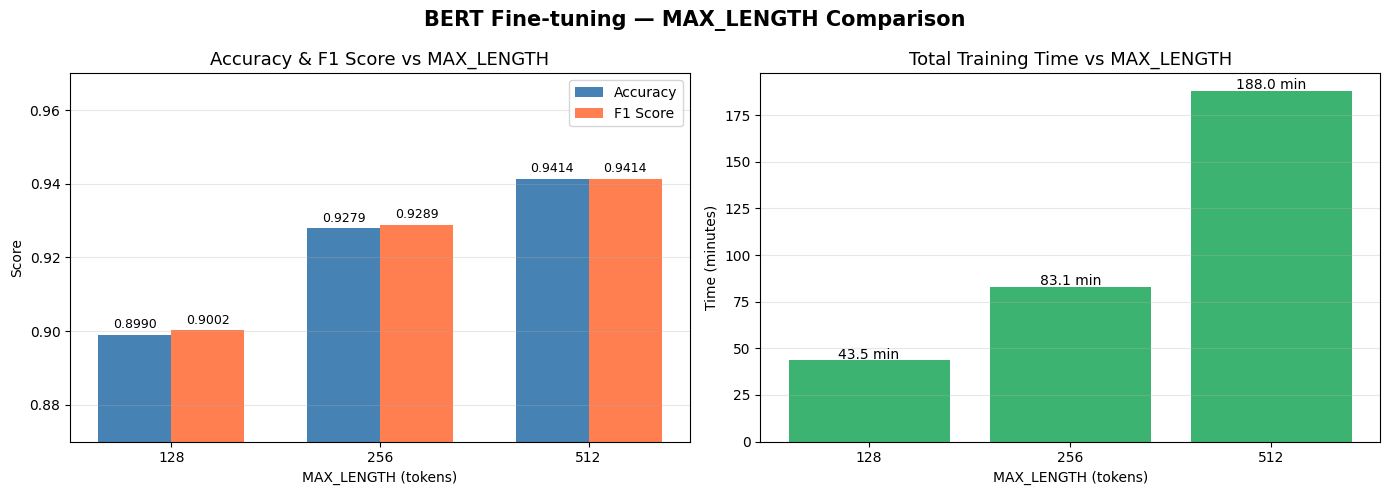

Plot saved!


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Store manually input/hardcoded results from previous 3 training runs to generate graphs quickly
results = {
    128: {"accuracy": 0.8990, "f1": 0.9002, "total_time": 43.5,  "epoch_times": [12.9, 13.0, 13.0]},
    256: {"accuracy": 0.9279, "f1": 0.9289, "total_time": 83.1,  "epoch_times": [25.2, 25.2, 25.2]},
    512: {"accuracy": 0.9414, "f1": 0.9414, "total_time": 188.0, "epoch_times": [62.5, 62.9, 62.9]},
}

# Build comparison table
rows = []
for ml, r in results.items():
    rows.append({
        "MAX_LENGTH":       ml,
        "Accuracy (%)":     f"{r['accuracy']*100:.2f}%",
        "F1 Score (%)":     f"{r['f1']*100:.2f}%",
        "Epoch 1 Time":     f"{r['epoch_times'][0]:.1f} min",
        "Epoch 2 Time":     f"{r['epoch_times'][1]:.1f} min",
        "Epoch 3 Time":     f"{r['epoch_times'][2]:.1f} min",
        "Total Train Time": f"{r['total_time']:.1f} min",
    })

df_results = pd.DataFrame(rows)
print("\n" + "="*75)
print("      COMPARISON TABLE — MAX_LENGTH IMPACT ON BERT PERFORMANCE")
print("="*75)
print(df_results.to_string(index=False))
print("="*75)

# Save CSV
df_results.to_csv("/content/drive/MyDrive/Licenta/comparison_table.csv", index=False)
print("\nTable saved!")

# Plot
labels = [str(k) for k in results.keys()]
accs   = [v["accuracy"]      for v in results.values()]
f1s    = [v["f1"]            for v in results.values()]
times  = [v["total_time"]    for v in results.values()]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x     = np.arange(len(labels))
width = 0.35
bars1 = axes[0].bar(x - width/2, accs, width, label="Accuracy", color="steelblue")
bars2 = axes[0].bar(x + width/2, f1s,  width, label="F1 Score",  color="coral")
axes[0].set_title("Accuracy & F1 Score vs MAX_LENGTH", fontsize=13)
axes[0].set_xlabel("MAX_LENGTH (tokens)")
axes[0].set_ylabel("Score")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels)
axes[0].set_ylim(0.87, 0.97)
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)
for bar in list(bars1) + list(bars2):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.001,
                 f"{bar.get_height():.4f}",
                 ha="center", va="bottom", fontsize=9)

axes[1].bar(labels, times, color="mediumseagreen")
axes[1].set_title("Total Training Time vs MAX_LENGTH", fontsize=13)
axes[1].set_xlabel("MAX_LENGTH (tokens)")
axes[1].set_ylabel("Time (minutes)")
axes[1].grid(axis="y", alpha=0.3)
for i, t in enumerate(times):
    axes[1].text(i, t + 1, f"{t:.1f} min", ha="center", fontsize=10)

plt.suptitle("BERT Fine-tuning — MAX_LENGTH Comparison",
             fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Licenta/comparison_maxlength.png", dpi=150)
plt.show()
print("Plot saved!")